In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

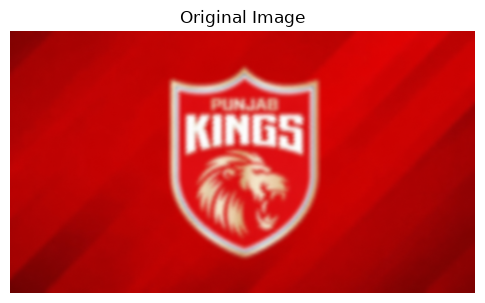

In [2]:
imread = cv2.imread(
    r"C:\Users\devah\Documents\ICT MU\Sem 5\DSIP\Lab\Images\PBKS blur.png"
)

image = cv2.cvtColor(imread, cv2.COLOR_BGR2RGB)

gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)

plt.figure(figsize=(6, 5))
plt.imshow(image)
plt.title("Original Image")
plt.axis("off")
plt.show()

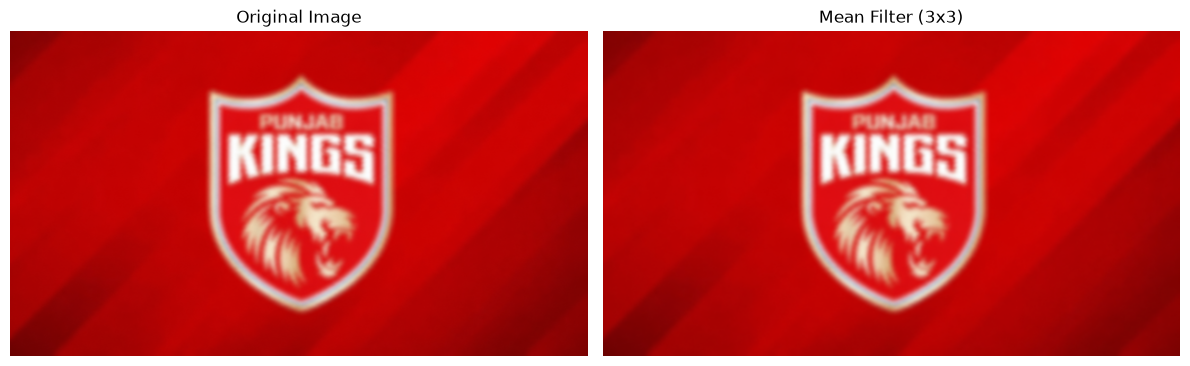

In [3]:
mean_3x3 = cv2.blur(image, (3, 3))

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(mean_3x3)
plt.title("Mean Filter (3x3)")
plt.axis("off")

plt.tight_layout()
plt.show()

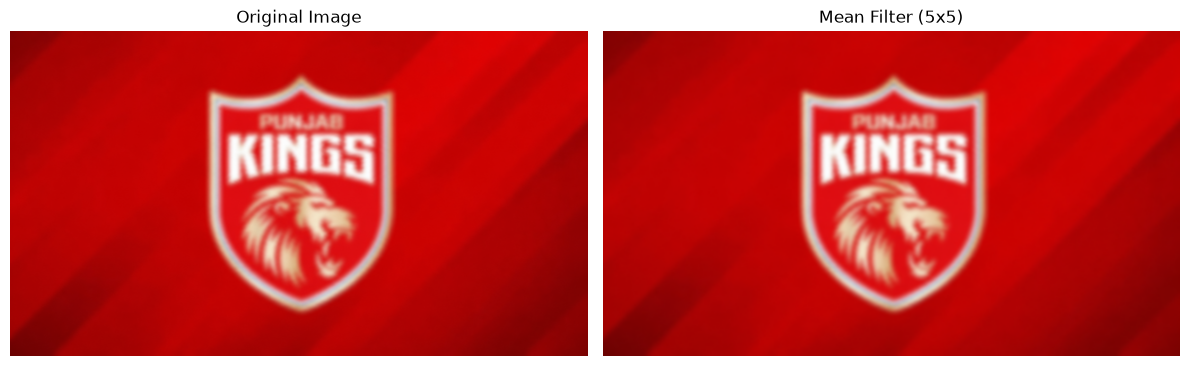

In [4]:
mean_5x5 = cv2.blur(image, (5, 5))

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(mean_5x5)
plt.title("Mean Filter (5x5)")
plt.axis("off")

plt.tight_layout()
plt.show()

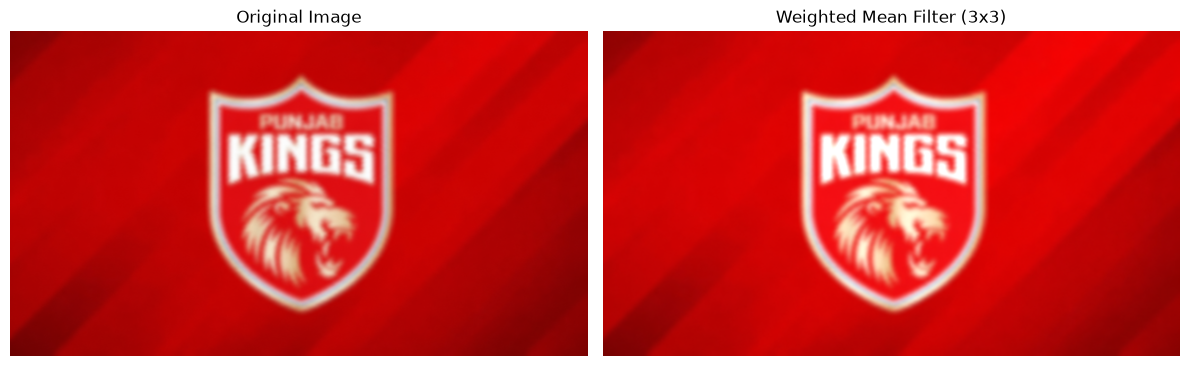

In [5]:
weighted_kernel = np.array([
    [1, 2, 1],
    [1, 2, 1],
    [1, 1, 1]
], dtype=np.float32)

weighted_kernel = weighted_kernel / 10

weighted_mean = cv2.filter2D(image, -1, weighted_kernel)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(weighted_mean)
plt.title("Weighted Mean Filter (3x3)")
plt.axis("off")

plt.tight_layout()
plt.show()

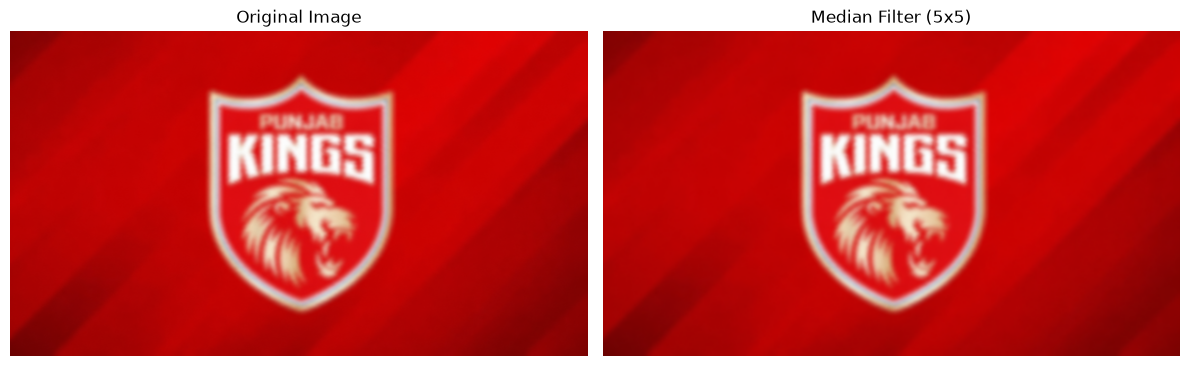

In [6]:
median_filtered = cv2.medianBlur(image, 5)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(median_filtered)
plt.title("Median Filter (5x5)")
plt.axis("off")

plt.tight_layout()
plt.show()

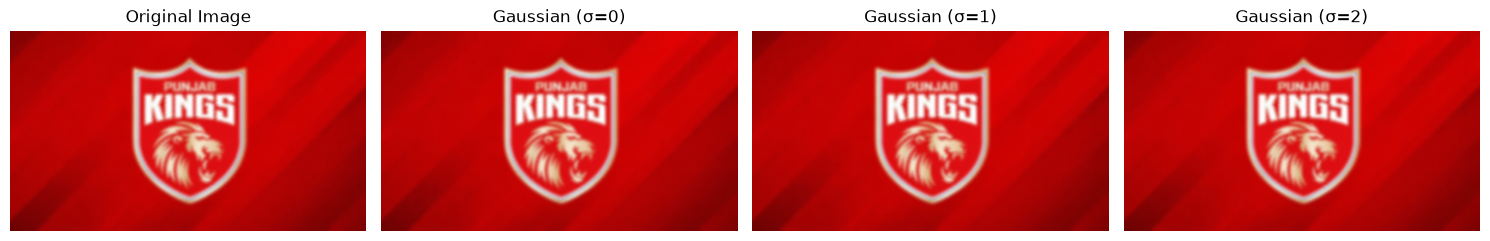

In [7]:
g0 = cv2.GaussianBlur(image, (5, 5), sigmaX=0)

g1 = cv2.GaussianBlur(image, (5, 5), sigmaX=1)

g2 = cv2.GaussianBlur(image, (5, 5), sigmaX=2)

plt.figure(figsize=(15, 4))

plt.subplot(1, 4, 1)
plt.imshow(image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 4, 2)
plt.imshow(g0)
plt.title("Gaussian (σ=0)")
plt.axis("off")

plt.subplot(1, 4, 3)
plt.imshow(g1)
plt.title("Gaussian (σ=1)")
plt.axis("off")

plt.subplot(1, 4, 4)
plt.imshow(g2)
plt.title("Gaussian (σ=2)")
plt.axis("off")

plt.tight_layout()
plt.show()

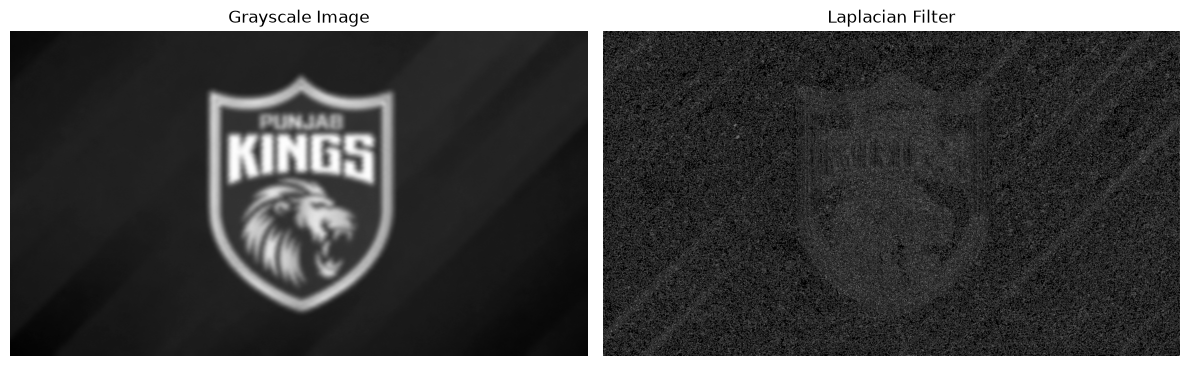

In [8]:
laplacian = cv2.Laplacian(gray, cv2.CV_64F)

laplacian_abs = cv2.convertScaleAbs(laplacian)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.imshow(gray, cmap="gray")
plt.title("Grayscale Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(laplacian_abs, cmap="gray")
plt.title("Laplacian Filter")
plt.axis("off")

plt.tight_layout()
plt.show()

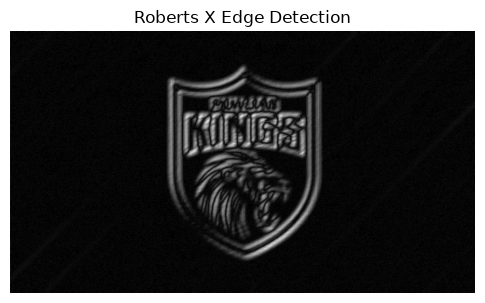

In [9]:
roberts_x = np.array([
    [1, 0],
    [0, -1]
], dtype=np.float32)

gx = cv2.filter2D(
    gray.astype(np.float32),
    cv2.CV_32F,
    roberts_x
)

roberts_x_image = cv2.normalize(
    np.abs(gx),
    None,
    0,
    255,
    cv2.NORM_MINMAX
).astype(np.uint8)

plt.figure(figsize=(6, 5))
plt.imshow(roberts_x_image, cmap="gray")
plt.title("Roberts X Edge Detection")
plt.axis("off")
plt.show()

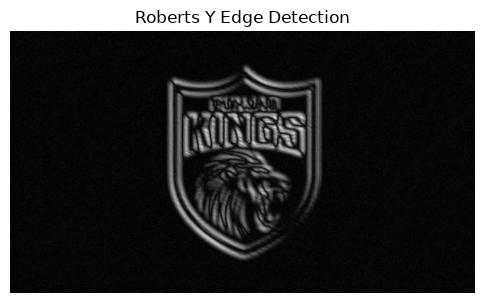

In [10]:
roberts_y = np.array([
    [0, 1],
    [-1, 0]
], dtype=np.float32)

gy = cv2.filter2D(
    gray.astype(np.float32),
    cv2.CV_32F,
    roberts_y
)

roberts_y_image = cv2.normalize(
    np.abs(gy),
    None,
    0,
    255,
    cv2.NORM_MINMAX
).astype(np.uint8)

plt.figure(figsize=(6, 5))
plt.imshow(roberts_y_image, cmap="gray")
plt.title("Roberts Y Edge Detection")
plt.axis("off")
plt.show()

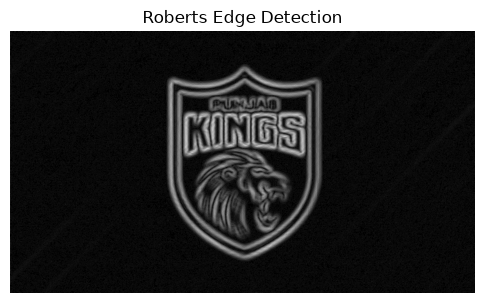

In [11]:
roberts_x = np.array([
    [1, 0],
    [0, -1]
], dtype=np.float32)

roberts_y = np.array([
    [0, 1],
    [-1, 0]
], dtype=np.float32)

gx = cv2.filter2D(
    gray.astype(np.float32),
    cv2.CV_32F,
    roberts_x
)

gy = cv2.filter2D(
    gray.astype(np.float32),
    cv2.CV_32F,
    roberts_y
)

roberts = cv2.magnitude(gx, gy)

roberts = cv2.normalize(
    roberts,
    None,
    0,
    255,
    cv2.NORM_MINMAX
).astype(np.uint8)

plt.figure(figsize=(6, 5))
plt.imshow(roberts, cmap="gray")
plt.title("Roberts Edge Detection")
plt.axis("off")
plt.show()

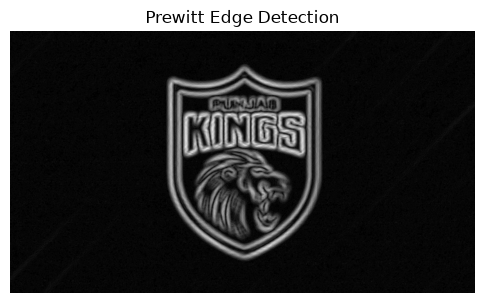

In [12]:
prewitt_x = np.array([
    [-1, 0, 1],
    [-1, 0, 1],
    [-1, 0, 1]
], dtype=np.float32)

prewitt_y = np.array([
    [-1, -1, -1],
    [0, 0, 0],
    [1, 1, 1]
], dtype=np.float32)

px = cv2.filter2D(
    gray.astype(np.float32),
    cv2.CV_32F,
    prewitt_x
)

py = cv2.filter2D(
    gray.astype(np.float32),
    cv2.CV_32F,
    prewitt_y
)

prewitt = cv2.magnitude(px, py)

prewitt = cv2.normalize(
    prewitt,
    None,
    0,
    255,
    cv2.NORM_MINMAX
).astype(np.uint8)

plt.figure(figsize=(6, 5))
plt.imshow(prewitt, cmap="gray")
plt.title("Prewitt Edge Detection")
plt.axis("off")
plt.show()

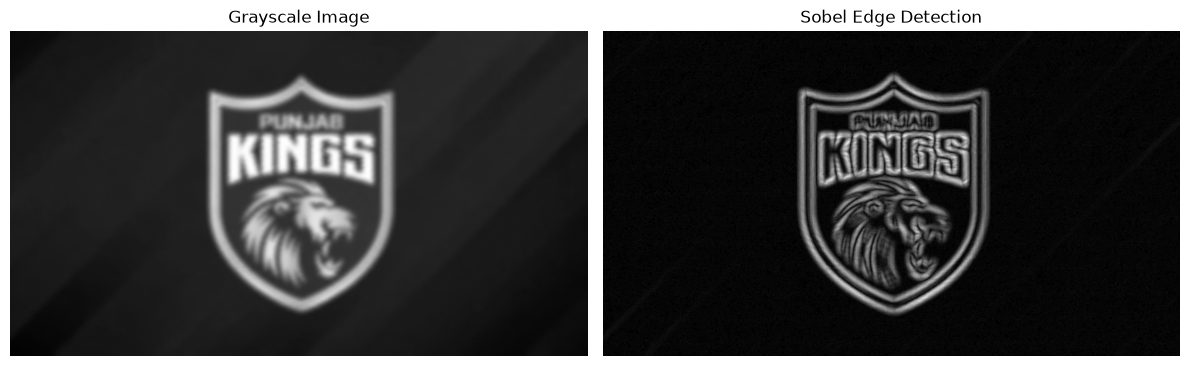

In [13]:
sobel_x = cv2.Sobel(
    gray,
    cv2.CV_64F,
    1,
    0,
    ksize=3
)

sobel_y = cv2.Sobel(
    gray,
    cv2.CV_64F,
    0,
    1,
    ksize=3
)

sobel_x = cv2.convertScaleAbs(sobel_x)
sobel_y = cv2.convertScaleAbs(sobel_y)

sobel_magnitude = cv2.addWeighted(
    sobel_x,
    0.5,
    sobel_y,
    0.5,
    0
)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.imshow(gray, cmap="gray")
plt.title("Grayscale Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(sobel_magnitude, cmap="gray")
plt.title("Sobel Edge Detection")
plt.axis("off")

plt.tight_layout()
plt.show()

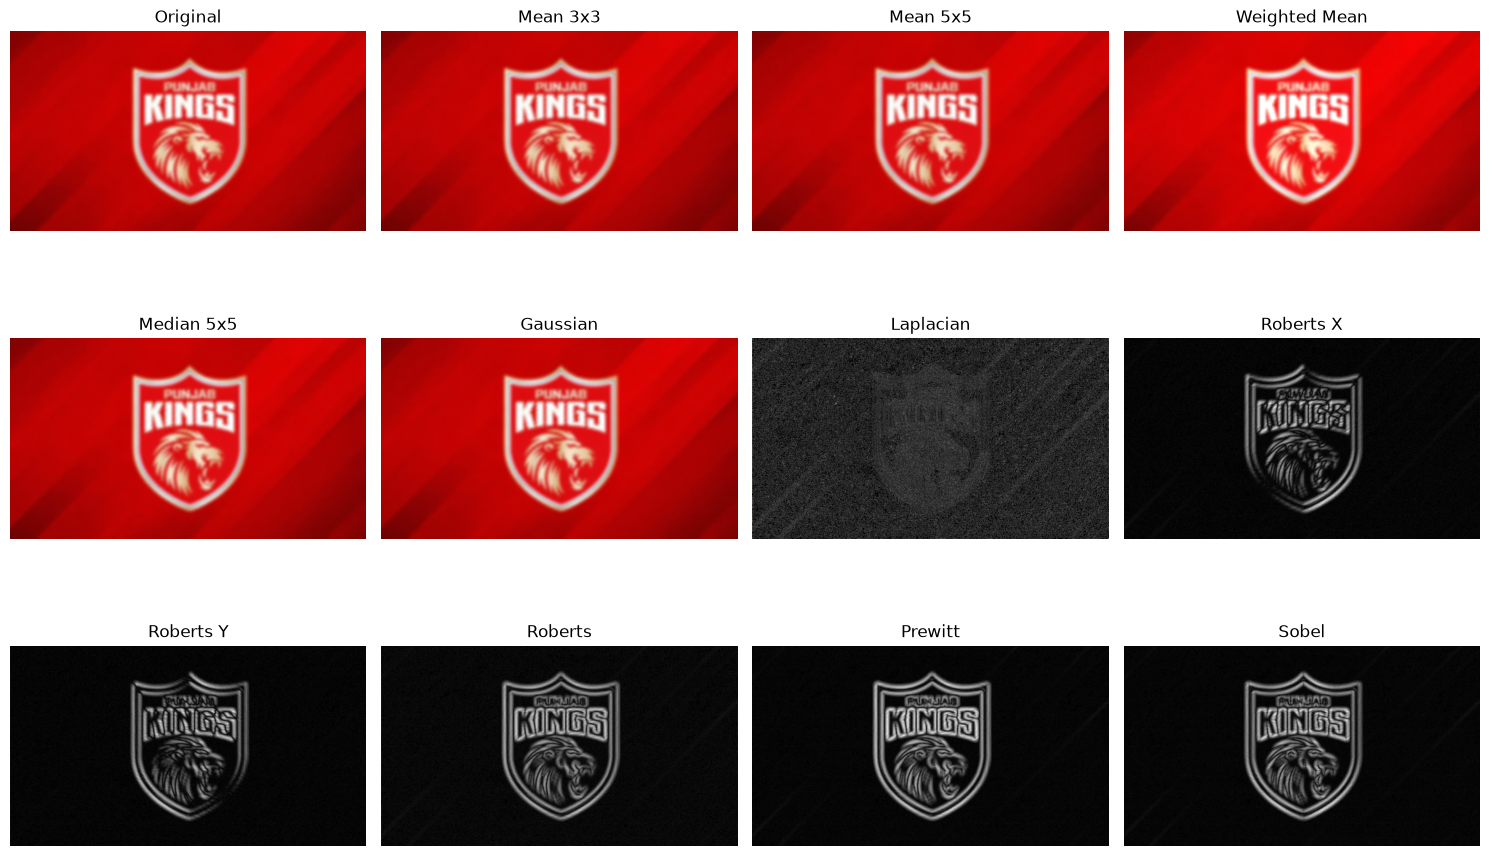

In [14]:
plt.figure(figsize=(15, 10))

plt.subplot(3, 4, 1)
plt.imshow(image)
plt.title("Original")
plt.axis("off")

plt.subplot(3, 4, 2)
plt.imshow(mean_3x3)
plt.title("Mean 3x3")
plt.axis("off")

plt.subplot(3, 4, 3)
plt.imshow(mean_5x5)
plt.title("Mean 5x5")
plt.axis("off")

plt.subplot(3, 4, 4)
plt.imshow(weighted_mean)
plt.title("Weighted Mean")
plt.axis("off")

plt.subplot(3, 4, 5)
plt.imshow(median_filtered)
plt.title("Median 5x5")
plt.axis("off")

plt.subplot(3, 4, 6)
plt.imshow(g1)
plt.title("Gaussian")
plt.axis("off")

plt.subplot(3, 4, 7)
plt.imshow(laplacian_abs, cmap="gray")
plt.title("Laplacian")
plt.axis("off")

plt.subplot(3, 4, 8)
plt.imshow(roberts_x_image, cmap="gray")
plt.title("Roberts X")
plt.axis("off")

plt.subplot(3, 4, 9)
plt.imshow(roberts_y_image, cmap="gray")
plt.title("Roberts Y")
plt.axis("off")

plt.subplot(3, 4, 10)
plt.imshow(roberts, cmap="gray")
plt.title("Roberts")
plt.axis("off")

plt.subplot(3, 4, 11)
plt.imshow(prewitt, cmap="gray")
plt.title("Prewitt")
plt.axis("off")

plt.subplot(3, 4, 12)
plt.imshow(sobel_magnitude, cmap="gray")
plt.title("Sobel")
plt.axis("off")

plt.tight_layout()
plt.show()